# Week 3 - Noise filtering
Necessary imports

In [14]:
from __future__ import annotations
import cv2
import matplotlib.pyplot as plt
import pickle
from dataclasses import dataclass
from pathlib import Path
import random
import math

import numpy as np
from scipy.ndimage import gaussian_filter1d, binary_fill_holes, gaussian_filter1d

In [7]:
def find_project_root():
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (directory / "data").is_dir() and (directory / "src").is_dir():
            return directory
    raise FileNotFoundError("Could not find the project root")


ROOT = find_project_root()
DATA_DIR = ROOT / "data"

## 0. Image and ground truth loading
Code snippet from week1 code so it stays with a persistent method

In [8]:
@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    # Sorting is essential: submission row i must correspond to query image i.
    paths = tuple(sorted(directory.glob("*.jpg")))
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


In [17]:
train_dataset = load_image_dataset(f"{DATA_DIR}/qsd1_w3")
non_augmented_data = load_image_dataset(f"{DATA_DIR}/qsd1_w3/non_augmented")
ground_truth = load_ground_truth(f"{DATA_DIR}/qsd1_w3/gt_corresps.pkl")

## Noise observation and analysis
Analyzing the type of noise that is present in the images will help us find the correct filters to reduce it successfully.
To do so we must observe the images and find which noise patterns emerge when plotted.

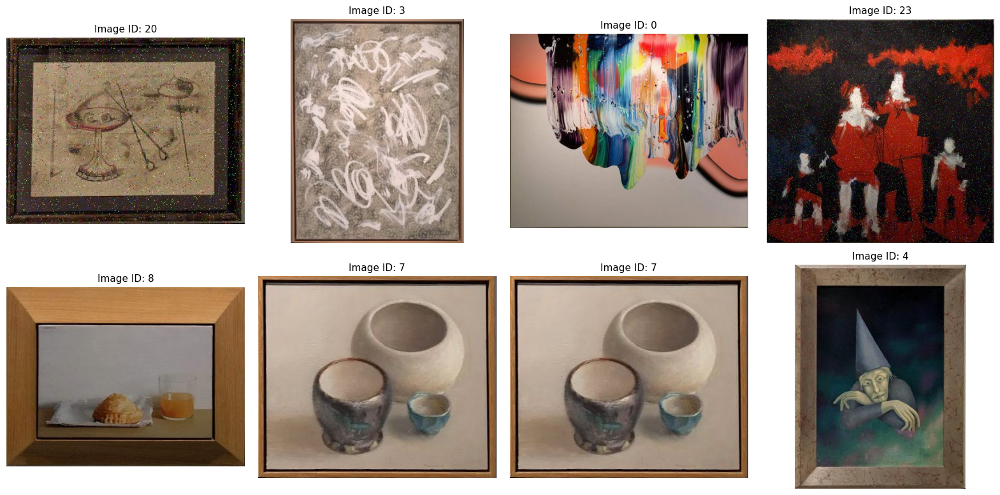

In [16]:
random.seed(42)
n_images = 8

n_cols = 4 
n_rows = math.ceil(n_images / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(n_cols * 4, n_rows * 4)
)

# Make axes iterable even if there's only one row or column
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for i in range(n_images):
    random_index = random.randint(0, len(train_dataset.paths) - 1)
    image_path = train_dataset.paths[random_index]
    image_id_value = train_dataset.ids[random_index]

    # Load image and convert BGR to RGB
    image = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(image_rgb)
    axes[i].set_title(f"Image ID: {image_id_value}", fontsize=11)
    axes[i].axis("off")

# Hide unused grid cells
for j in range(n_images, len(axes)):
    axes[j].axis("off")

plt.tight_layout(pad=1.5)
plt.show()


In this sample we can see that image 20 has a considerable ammount of noise present on it, to further analyse which type of noise it is we can plot the original vs noisy image and it's difference.

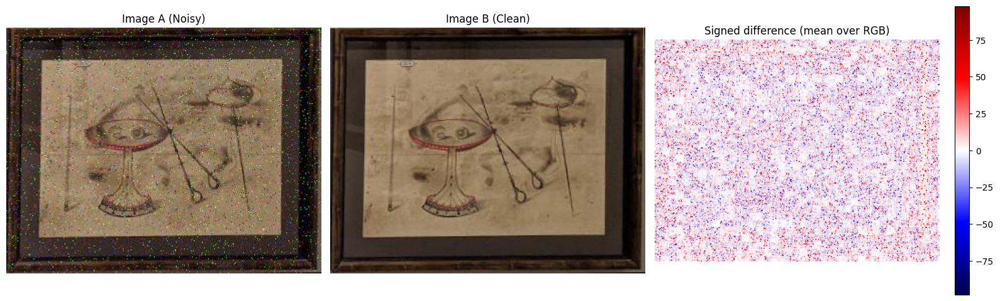

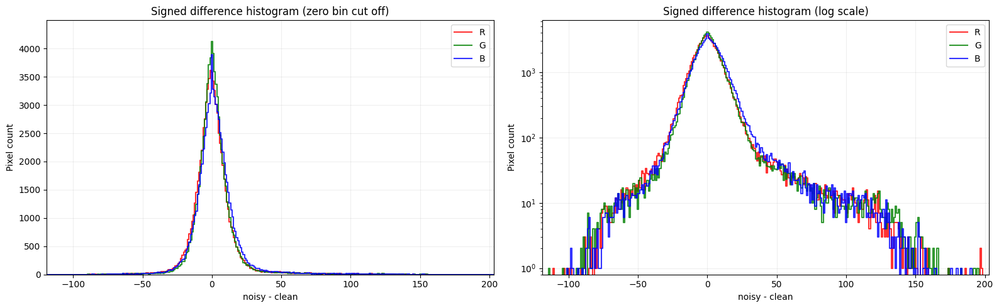

In [27]:
def compute_histograms_and_difference(a, b, plot=False):
    """
    Display noisy image, clean image, their signed difference,
    and the per-channel histograms of the difference.

    Returns
    -------
    image_a, image_b, difference (signed, noisy - clean), difference_histogram
    """

    def load_rgb(path):
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f"Could not load image: {path}")
        return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image_a = load_rgb(a)
    image_b = load_rgb(b)

    if image_a.shape != image_b.shape:
        raise ValueError(
            f"Image dimensions differ: {image_a.shape} vs {image_b.shape}"
        )

    # Signed difference (int16 avoids uint8 wraparound)
    difference = image_a.astype(np.int16) - image_b.astype(np.int16)

    # One integer bin per possible difference value: -255 ... 255
    bin_edges = np.arange(-255.5, 256.5, 1.0)
    values = np.arange(-255, 256)

    difference_histogram = np.concatenate([
        np.histogram(difference[:, :, c].ravel(), bins=bin_edges)[0]
        for c in range(3)
    ])

    if plot:
        n = len(values)
        hists = [difference_histogram[c * n:(c + 1) * n] for c in range(3)]
        colors = ["red", "green", "blue"]
        names = ["R", "G", "B"]

        # ---------- Images ----------
        lim = max(np.percentile(np.abs(difference), 99.5), 1)

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))
        axes[0].imshow(image_a)
        axes[0].set_title("Image A (Noisy)")
        axes[1].imshow(image_b)
        axes[1].set_title("Image B (Clean)")
        im = axes[2].imshow(difference.mean(axis=2), cmap="seismic",
                            vmin=-lim, vmax=lim)
        axes[2].set_title("Signed difference (mean over RGB)")
        plt.colorbar(im, ax=axes[2], fraction=0.046)
        for ax in axes:
            ax.axis("off")
        plt.tight_layout()
        plt.show()

        # ---------- Histograms ----------
        # Zoom the x-axis onto where the data actually lives
        nonzero = np.where(sum(hists) > 0)[0]
        x_min = max(values[nonzero.min()] - 5, -255)
        x_max = min(values[nonzero.max()] + 5, 255)

        fig, axes = plt.subplots(1, 2, figsize=(16, 5))

        for h, col, name in zip(hists, colors, names):
            axes[0].step(values, h, where="mid", color=col, alpha=0.8, label=name)
            axes[1].step(values, h, where="mid", color=col, alpha=0.8, label=name)

        # Left: linear scale, with the zero bin cut off so the rest is visible
        peak_wo_zero = max(np.delete(h, 255).max() for h in hists)
        axes[0].set_ylim(0, peak_wo_zero * 1.15)
        axes[0].set_title("Signed difference histogram (zero bin cut off)")

        # Right: log scale, shows the tails
        axes[1].set_yscale("log")
        axes[1].set_ylim(bottom=0.8)
        axes[1].set_title("Signed difference histogram (log scale)")

        for ax in axes:
            ax.set_xlim(x_min, x_max)
            ax.set_xlabel("noisy - clean")
            ax.set_ylabel("Pixel count")
            ax.grid(alpha=0.2)
            ax.legend()

        plt.tight_layout()
        plt.show()

    return image_a, image_b, difference, difference_histogram



noisy_image = train_dataset.paths[20]
clean_image = non_augmented_data.paths[20]
# Example
image_a, image_b, difference, difference_histogram = (
    compute_histograms_and_difference(noisy_image, clean_image, plot=True)
)

With this distribution of the noise we can distinguish a form that starts with a gaussian-like shape but turns greater on the wings of it. This heavily leads us to thinking that this could be some kind of gaussian noise or even a type of impulse/salt-pepper noise, as we can see that the gaussian presents a small deviation $\sigma$ on the non logarithmic representation of the data, for this cases the most common implementations are the median and average filters, which we will apply and compare the results.

## Filter comparison

In [35]:
filtered_image_median = cv2.medianBlur(image_a, 3)

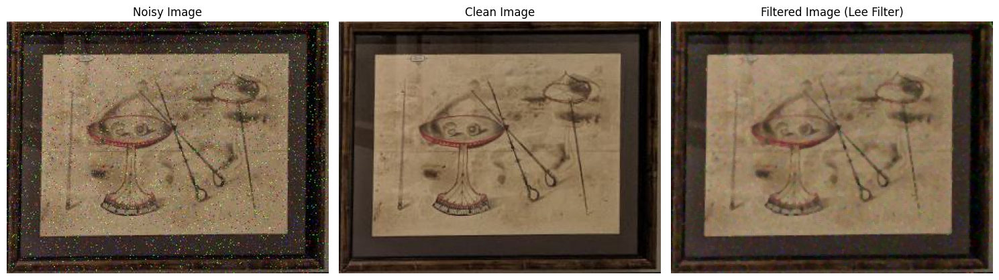

In [36]:
# compare the original noisy image, the clean image, and the filtered image
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image_a)
plt.title("Noisy Image")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(image_b)
plt.title("Clean Image")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(filtered_image_median)
plt.title("Filtered Image (Lee Filter)")
plt.axis("off")
plt.tight_layout()
plt.show()


## Filter performance analysis

In [37]:
filters = {
    "Median Filter": lambda img: cv2.medianBlur(img, 3),
    "Gaussian Filter": lambda img: cv2.GaussianBlur(img, (3, 3), 0),
    "Mean Filter": lambda img: cv2.blur(img, (3, 3)),
    "Bilateral Filter": lambda img: cv2.bilateralFilter(img, 9, 75, 75),
    "Non local Means Filter": lambda img: cv2.fastNlMeansDenoisingColored(img, None, 10, 10, 7, 21),}



## Filter evaluation against the non-augmented dataset
Each noisy image is filtered and compared with the clean image having the same numeric ID. The plots show the mean and standard deviation across the dataset.

In [40]:
from skimage.metrics import structural_similarity

def read_rgb(path: Path) -> np.ndarray:
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def evaluate_filters(
    noisy_dataset: ImageDataset,
    clean_dataset: ImageDataset,
    filter_functions: dict[str, callable],
) -> dict[str, dict[str, np.ndarray | float]]:
    """Compute per-image MSE and SSIM for every filter."""
    clean_by_id = dict(zip(clean_dataset.ids.tolist(), clean_dataset.paths))
    missing_ids = sorted(set(noisy_dataset.ids.tolist()) - set(clean_by_id))
    if missing_ids:
        raise ValueError(f"No clean counterpart for image IDs: {missing_ids}")

    metrics = {}
    for filter_name, filter_function in filter_functions.items():
        mse_values = []
        ssim_values = []
        for noisy_path, image_id_value in zip(noisy_dataset.paths, noisy_dataset.ids):
            noisy = read_rgb(noisy_path)
            clean = read_rgb(clean_by_id[int(image_id_value)])
            if noisy.shape != clean.shape:
                raise ValueError(
                    f"Image shape mismatch for ID {image_id_value}: "
                    f"{noisy.shape} vs {clean.shape}"
                )

            filtered = filter_function(noisy)
            mse_values.append(np.mean((filtered.astype(np.float32) - clean) ** 2))
            ssim_values.append(
                structural_similarity(clean, filtered, channel_axis=2, data_range=255)
            )

        metrics[filter_name] = {
            "mse": np.asarray(mse_values),
            "ssim": np.asarray(ssim_values),
        }
    return metrics


filter_metrics = evaluate_filters(train_dataset, non_augmented_data, filters)

summary = []
for filter_name, values in filter_metrics.items():
    summary.append({
        "Filter": filter_name,
        "MSE mean": values["mse"].mean(),
        "MSE std": values["mse"].std(),
        "SSIM mean": values["ssim"].mean(),
        "SSIM std": values["ssim"].std(),
    })

import pandas as pd
summary_df = pd.DataFrame(summary).set_index("Filter")
display(summary_df.round(4))

,MSE mean,MSE std,SSIM mean,SSIM std
Filter,,,,
Median Filter,71.870102,116.600800,0.9005,0.0860
Gaussian Filter,77.183998,109.972900,0.8929,0.1065
Mean Filter,99.123001,125.905701,0.8737,0.1007
Bilateral Filter,84.435204,108.995499,0.8312,0.1178
Non local Means Filter,94.221397,123.580498,0.8281,0.1190


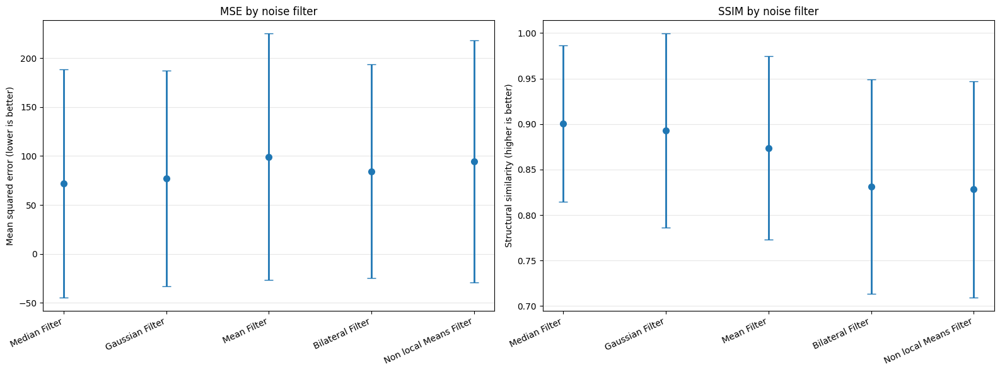

In [41]:
filter_names = list(filter_metrics)
x = np.arange(len(filter_names))
means = {metric: [filter_metrics[name][metric].mean() for name in filter_names]
         for metric in ("mse", "ssim")}
stds = {metric: [filter_metrics[name][metric].std() for name in filter_names]
        for metric in ("mse", "ssim")}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for axis, metric, title, ylabel in zip(
    axes,
    ("mse", "ssim"),
    ("MSE by noise filter", "SSIM by noise filter"),
    ("Mean squared error (lower is better)", "Structural similarity (higher is better)"),
):
    axis.errorbar(
        x, means[metric], yerr=stds[metric], fmt="o", capsize=5,
        linewidth=2, markersize=7,
    )
    axis.set_xticks(x, filter_names, rotation=25, ha="right")
    axis.set_title(title)
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

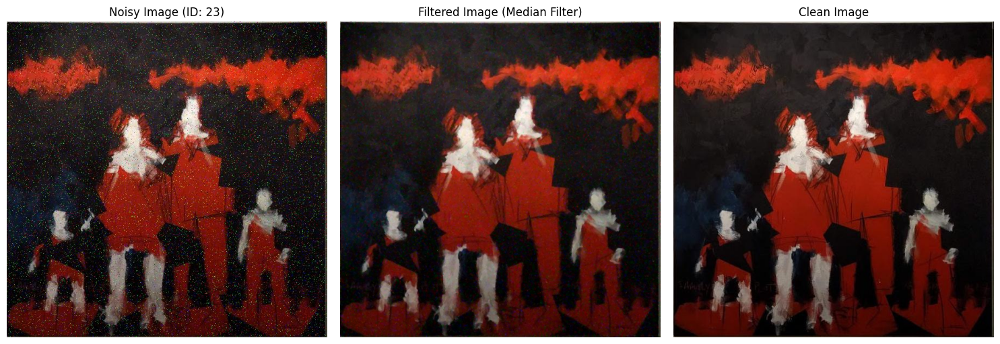

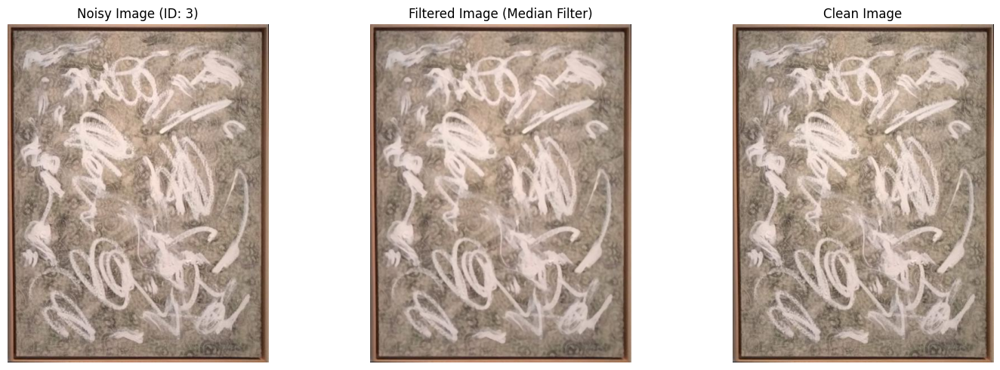

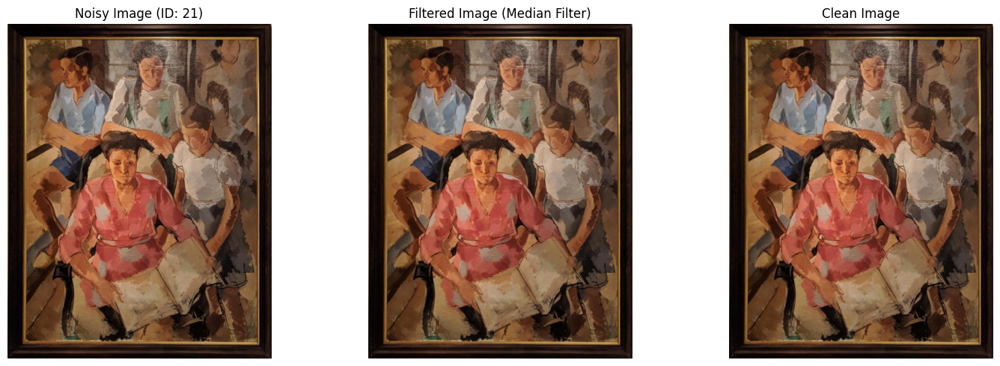

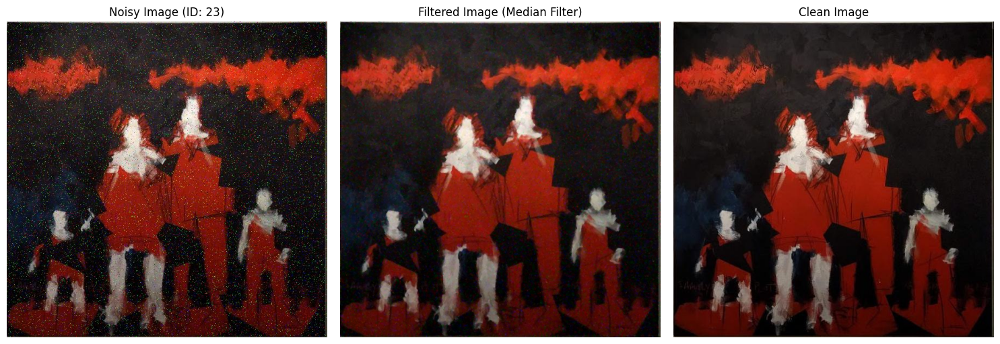

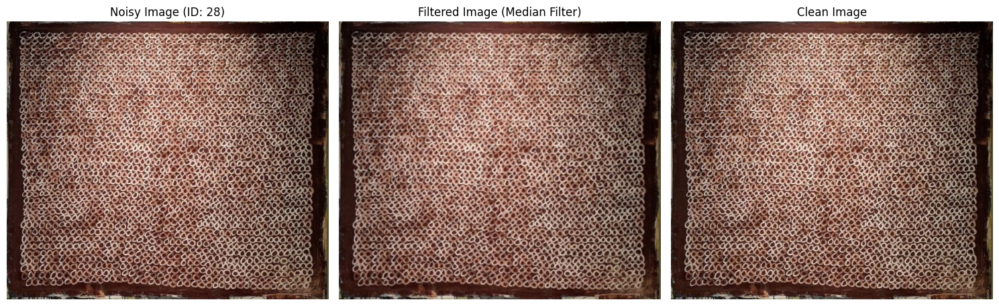

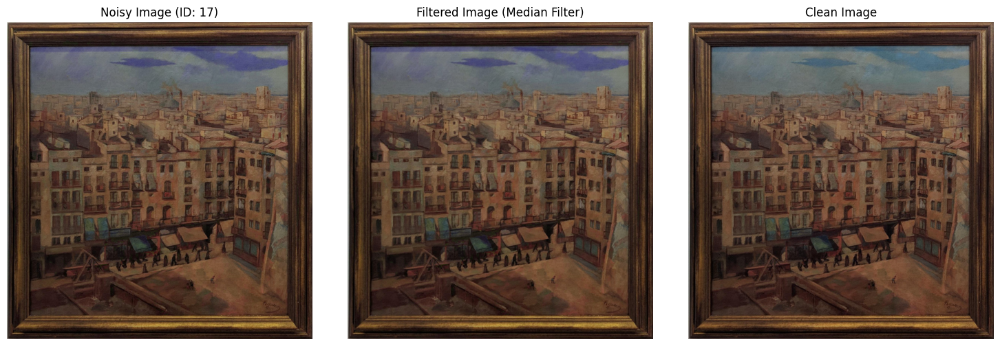

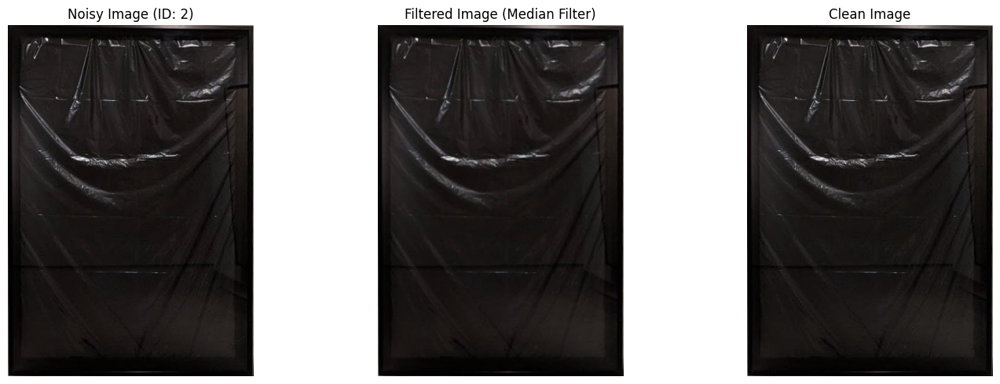

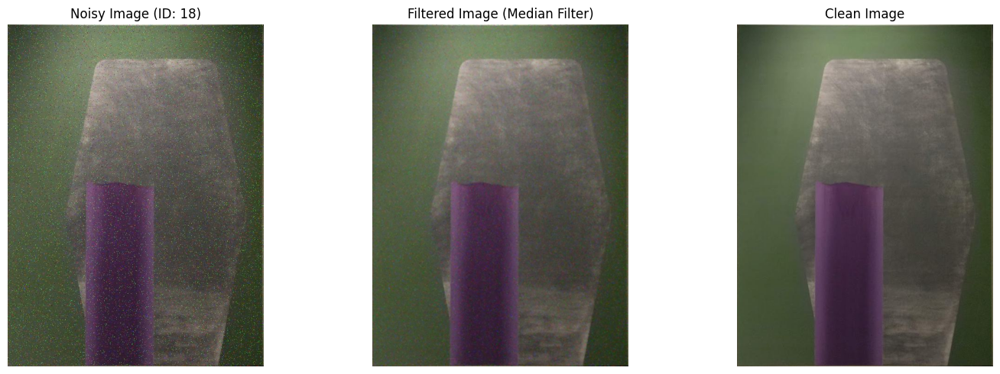

In [42]:
# Display the original noisy image, the filtered image, and the clean image for comparison for a random sample of images
n_images = 8

for i in range(n_images):
    random_index = random.randint(0, len(train_dataset.paths) - 1)
    image_path = train_dataset.paths[random_index]
    image_id_value = train_dataset.ids[random_index]

    # Load images
    noisy_image = read_rgb(image_path)
    clean_image = read_rgb(non_augmented_data.paths[random_index])
    filtered_image = cv2.medianBlur(noisy_image, 3)

    # Display images
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(noisy_image)
    plt.title(f"Noisy Image (ID: {image_id_value})")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(filtered_image)
    plt.title("Filtered Image (Median Filter)")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(clean_image)
    plt.title("Clean Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()